# Integrate a singular field over a triangle
Run with OneSimulation, NumPy and Matplotlib installed.
Vary the tensor order. Predict which transformed integrand is exactly integrated first.

Order 4 errors: Cartesian map 0.00311717, radial map 1.11e-16


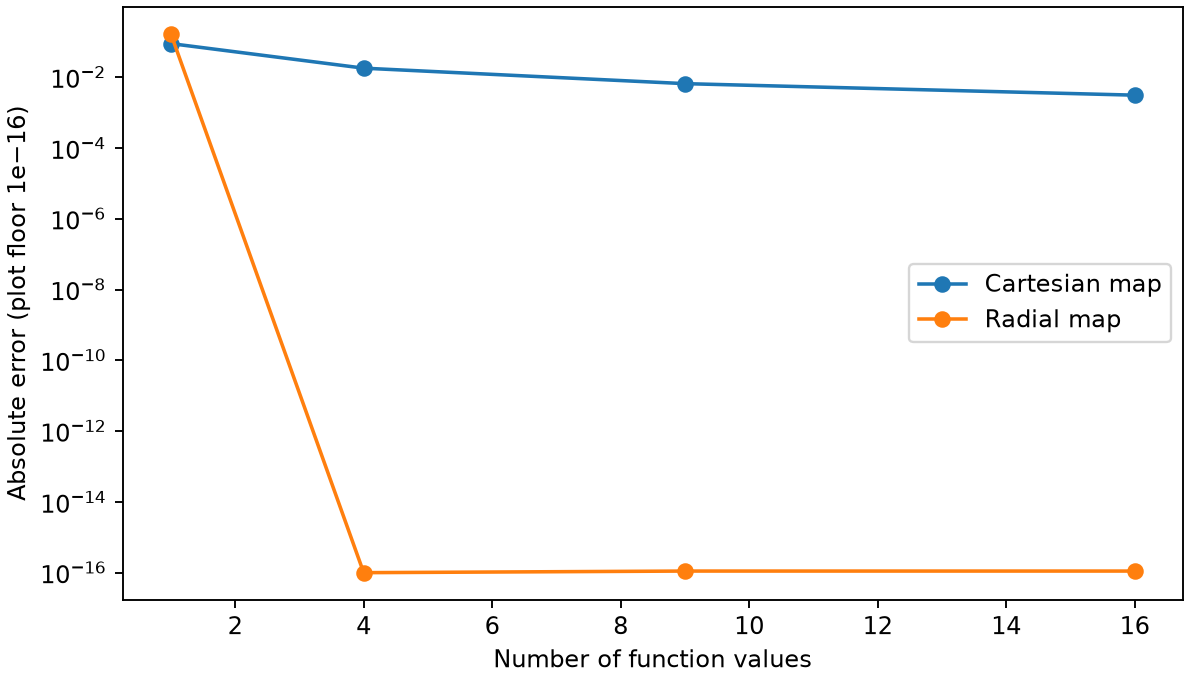

In [1]:
"""Integrate a corner singularity over the unit right triangle by two maps."""
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.discretization.geometry.carriers.kernels.quadrature.rules.reference_quadrature import gauss_legendre

orders = [1, 2, 3, 4]
errors = [[], []]
for order in orders:
    points, weights = np.asarray(gauss_legendre(order)).T
    nodes, weights = (points+1)/2, weights/2
    u, v = np.meshgrid(nodes, nodes, indexing="ij")
    # First map x=u, y=(1-u)v. Second map x=u²(1-v), y=u²v.
    values = [(1-u) / np.sqrt(u+(1-u)*v), 2*u**2 * np.ones_like(v)]
    for sequence, integrand in zip(errors, values):
        sequence.append(abs(weights @ integrand @ weights - 2/3))
print(f"Order {orders[-1]} errors: Cartesian map {errors[0][-1]:.6g}, radial map {errors[1][-1]:.3g}")
assert max(errors[1][1:]) < 1e-13
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for err, label in zip(errors, ["Cartesian map", "Radial map"]):
    ax.semilogy(np.square(orders), np.maximum(err, 1e-16), "o-", label=label)
ax.set(xlabel="Number of function values", ylabel="Absolute error (plot floor 1e−16)")
ax.legend()
fig.savefig("numerics-triangle-cubature.png", dpi=170)
